# Exploratory Data Analysis of SDSS DR17

## 1. Introduction

This project explores a sample of astronomical objects from the Sloan Digital Sky Survey (SDSS) Data Release 17 (DR17).

The goal is to perform an exploratory data analysis (EDA), investigating object classifications, redshift distributions, and spatial coordinates using Python.


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns

In [35]:
# --- load data ---
df = pd.read_csv(
    '../data/sdss_dr17_sample.csv',
    skiprows=1 #to exclude the first row which contains the column names
)

In [36]:
# --- visualize data ---
df.head()

,specObjID,class,subclass,z,ra,dec
0,7220532273447458816,GALAXY,NaN,0.472712,167.01210,25.374580
1,7220532548325365760,QSO,NaN,0.511426,167.06209,25.160268
2,7220532823203272704,GALAXY,NaN,0.436013,166.89219,25.502323
3,7220533098081179648,GALAXY,NaN,0.313152,166.83881,25.589335
4,7220533372959086592,GALAXY,NaN,0.345445,167.12080,25.428866


In [37]:
# --- catalog information ---
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   specObjID  100 non-null    int64  
 1   class      100 non-null    object 
 2   subclass   20 non-null     object 
 3   z          100 non-null    float64
 4   ra         100 non-null    float64
 5   dec        100 non-null    float64
dtypes: float64(3), int64(1), object(2)
memory usage: 4.8+ KB


In [38]:
# --- descriptive statistics \\ verifying null values ---
df.isnull().sum()

specObjID     0
class         0
subclass     80
z             0
ra            0
dec           0
dtype: int64

In [39]:
# --- descriptive statistics ---
df.describe()

,specObjID,z,ra,dec
count,1.000000e+02,100.000000,100.000000,100.000000
mean,7.220546e+18,0.784565,167.262866,26.158576
std,7.974618e+12,0.896478,0.260345,0.414252
min,7.220532e+18,-0.000390,166.817680,25.160268
25%,7.220539e+18,0.398332,167.026890,25.841242
50%,7.220546e+18,0.529899,167.280645,26.089767
75%,7.220553e+18,0.657712,167.492402,26.493795
max,7.220559e+18,4.236082,167.728360,26.973139


In [40]:
# --- class distribution // obj for class ---
df['class'].value_counts()

class
GALAXY    68
QSO       22
STAR      10
Name: count, dtype: int64

## 2. Dataset

The dataset was obtained from the SDSS DR17 SkyServer database using an SQL query.

The sample contains 100 astronomical objects and the following variables:
- `specObjID`: Unique identifier of the spectroscopic object.
- `class`: Main object classification.
- `subclass`: More specific object classification.
- `z`: Redshift.
- `ra`: Right Ascension.
- `dec`: Declination.

In [41]:
# --- subclass distribution // obj for subclass ---
df['subclass'].value_counts(dropna=False)

subclass
NaN               80
BROADLINE          8
STARFORMING        2
F0IV (81937)       2
CV                 2
B8III (220575)     1
WDcooler           1
F3/F5V (30743)     1
O8e (188001)       1
A4V (136729)       1
F8V (G_243-63)     1
Name: count, dtype: int64

In [42]:
# --- negative z values ---
df[df['z'] < 0]

,specObjID,class,subclass,z,ra,dec
27,7220539695150946304,STAR,F0IV (81937),-0.000037,167.08697,26.158274
42,7220543818319550464,STAR,B8III (220575),-0.000390,167.06732,25.671709
51,7220546292220712960,STAR,WDcooler,-0.000272,167.46448,26.905939
69,7220551240023037952,STAR,O8e (188001),-0.000010,167.49975,26.312612
85,7220555638069549056,STAR,A4V (136729),-0.000321,167.51696,25.716056


In [43]:
# --- descriptive statistics for z values by class ---
df.groupby('class')['z'].describe()

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
GALAXY,68.0,0.494324,0.130976,0.134766,0.429309,0.525446,0.564991,0.733386
QSO,22.0,2.038294,1.233461,0.385396,0.751882,2.175244,2.824547,4.236082
STAR,10.0,-0.000004,0.000259,-0.000390,-0.000213,0.000026,0.000130,0.000359


In [44]:
# --- coordinates descriptive statistics ---
df[['ra', 'dec']].describe()

,ra,dec
count,100.000000,100.000000
mean,167.262866,26.158576
std,0.260345,0.414252
min,166.817680,25.160268
25%,167.026890,25.841242
50%,167.280645,26.089767
75%,167.492402,26.493795
max,167.728360,26.973139


## 3. Data Loading

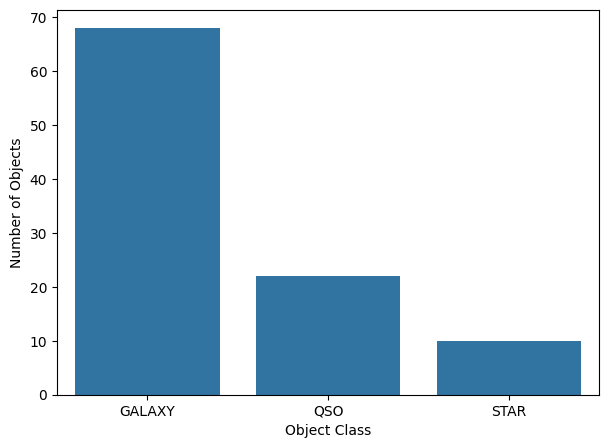

In [ ]:
# --- distribution ---
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='class')

plt.xlabel('Object Class')
plt.ylabel('Number of Objects')

plt.show()
plt.savefig('../results/figures/class_distribution.png', dpi=300, bbox_inches='tight')

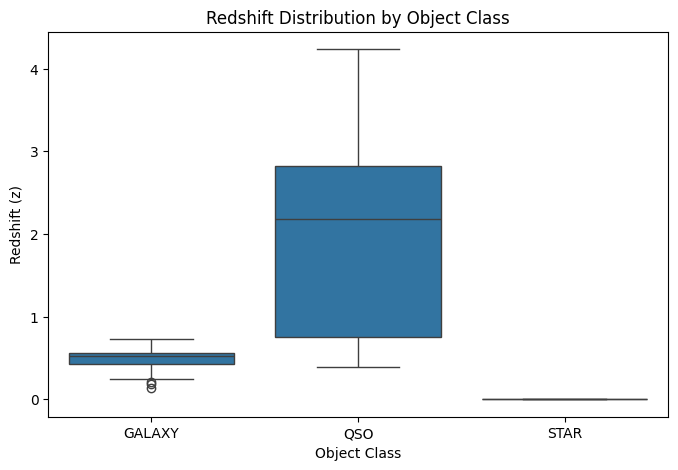

In [ ]:
# --- z distribution ---
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='class', y='z')

plt.title('Redshift Distribution by Object Class')
plt.xlabel('Object Class')
plt.ylabel('Redshift (z)')

plt.show()
plt.savefig('../results/figures/z_distribution.png', dpi=300, bbox_inches='tight')

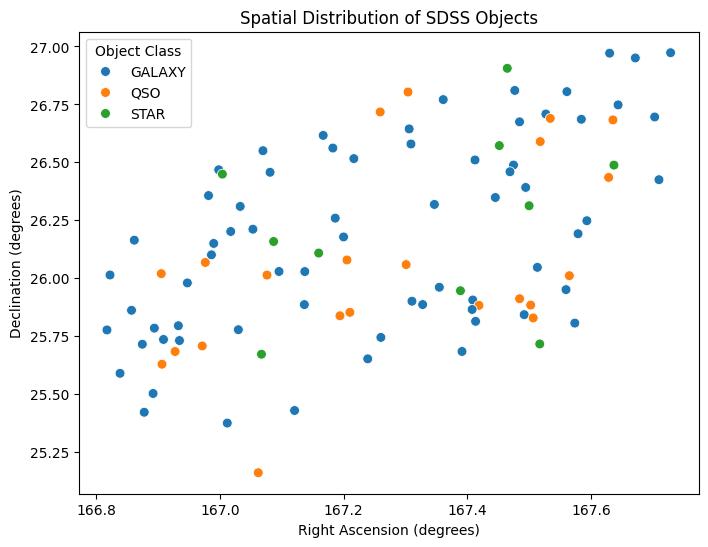

In [ ]:
# --- spatial distribution ---
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df, x='ra', y='dec', hue='class', s=50)

plt.title('Spatial Distribution of SDSS Objects')
plt.xlabel('Right Ascension (degrees)')
plt.ylabel('Declination (degrees)')

plt.legend(title='Object Class')
plt.show()
plt.savefig('../results/figures/spatial_distribution.png', dpi=300, bbox_inches='tight')

and the next steps...

## 4. Initial Data Exploration

## 5. Data Quality Assessment

## 6. Exploratory Data Analysis


## 7. Results and Discussion

The exploratory analysis revealed differences in redshift distributions among the three main object classes: galaxies, quasars, and stars.

Galaxies presented relatively low redshift values, while quasars showed a broader distribution extending to higher redshifts. Stars exhibited redshift values close to zero, including small negative values.

The spatial distribution also allowed the visualization of the astronomical objects within the selected region of the sky.

## 8. Limitations

This analysis was performed using a sample of 100 objects retrieved from SDSS DR17. Since the query used a TOP 100 selection without random sampling, the dataset should not be considered representative of the entire SDSS population.

Therefore, the results are exploratory and should not be generalized to the full astronomical catalog.

Further analysis could benefit from a larger and systematically selected dataset.